# ABCD matrices: paraxial rays, Gaussian beams and resonators

`pyoptics.abcd` describes paraxial optical systems by 2×2 ray transfer
matrices. A ray with height $y$ and reduced angle $u = n\theta$ is mapped by

$$ \begin{pmatrix} y_\mathrm{out} \\ u_\mathrm{out} \end{pmatrix} =
\begin{pmatrix} A & B \\ C & D \end{pmatrix}
\begin{pmatrix} y_\mathrm{in} \\ u_\mathrm{in} \end{pmatrix}, \qquad AD - BC = 1. $$

The same four numbers transform the complex beam parameter of a Gaussian beam,
$1/q = 1/R - i\lambda_0/(\pi n w^2)$, by the ABCD law
$q_\mathrm{out}/n_\mathrm{out} = (A q_\mathrm{in}/n_\mathrm{in} + B)/(C q_\mathrm{in}/n_\mathrm{in} + D)$,
and they define Collins' generalisation of the Fresnel integral, which
propagates *any* field through the system.

| Element | Matrix |
|---|---|
| `free_space(d, n)` | $\begin{pmatrix} 1 & d/n \\ 0 & 1\end{pmatrix}$ |
| `thin_lens(f)` | $\begin{pmatrix} 1 & 0 \\ -1/f & 1\end{pmatrix}$ |
| `refraction(R, n1, n2)` | $\begin{pmatrix} 1 & 0 \\ -(n_2 - n_1)/R & 1\end{pmatrix}$ |
| `mirror(R, theta, plane)` | $\begin{pmatrix} 1 & 0 \\ -2/R_\mathrm{eff} & 1\end{pmatrix}$, $R_\mathrm{eff} = R\cos\theta$ (tangential) or $R/\cos\theta$ (sagittal) |
| `grin(d, n0, g)` | $\begin{pmatrix} \cos gd & \sin gd/(n_0 g) \\ -n_0 g\sin gd & \cos gd\end{pmatrix}$ |

`OpticalSystem` chains elements along $z$ and evaluates rays and beams
anywhere, also inside thick elements; further functions give cardinal points,
images, resonator eigenmodes, Gouy phases and mode matching efficiencies.

**Sign conventions:** light travels in $+z$; $R > 0$ if the centre of curvature
lies in $+z$; $f > 0$ converging; concave mirrors have $R > 0$ and are unfolded.
**Phase convention:** $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$, the Gouy
phase enters as $\exp(-i\psi)$ as in `pyoptics.beams`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from pyoptics import abcd
from pyoptics.abcd import OpticalSystem
from pyoptics.utils import grid2d

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})


def plot_rays(ax, system, rays, z, colors=None, **kwargs):
    # trace rays (2, N) and plot y(z)
    y, _ = system.trace(rays, z)
    for i in range(y.shape[1]):
        ax.plot(z, y[:, i], color=None if colors is None else colors[i], **kwargs)
    return y

## 1. Imaging with a thin lens

A lens with $f = 50$ mm images an object 80 mm in front of it. Three ray fans
leave the tip of the object (at $y = 5$ mm), the axis point and a point below
the axis. `image()` returns the image distance $s'$ and magnification $m$
straight from the system matrix: the image plane is where the total matrix
has $B = 0$, so all rays from one object point meet in one image point,
independent of their angle.

image distance s' = 133.3 mm (1/s + 1/s' = 1/f: 0.0200 = 0.0200), magnification m = -1.667


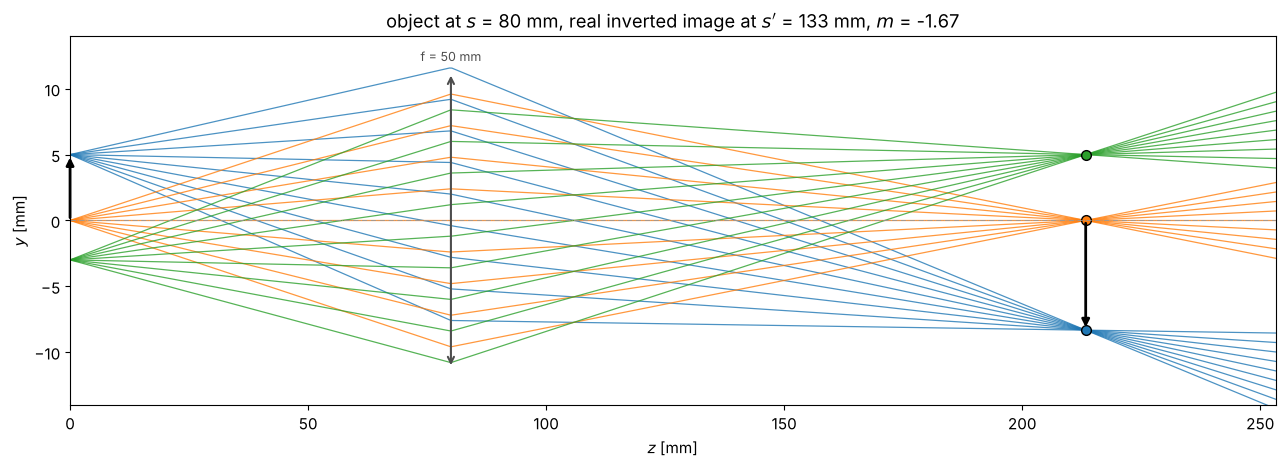

In [2]:
f, s = 50.0, 80.0
system = OpticalSystem().free_space(s).thin_lens(f, label="f = 50 mm").free_space(200)
s_img, m = abcd.image(abcd.thin_lens(f), s)
print(f"image distance s' = {s_img:.1f} mm (1/s + 1/s' = 1/f: {1/s + 1/s_img:.4f} = {1/f:.4f}), magnification m = {m:.3f}")

z = np.linspace(0, s + s_img + 40, 500)
fig, ax = plt.subplots(figsize=(13, 4.8))
for y0, color in ((5.0, "C0"), (0.0, "C1"), (-3.0, "C2")):
    angles = np.linspace(-0.12, 0.12, 9) - y0/s*0.6
    rays = np.vstack([np.full_like(angles, y0), angles])
    plot_rays(ax, system, rays, z, colors=[color]*len(angles), lw=0.9, alpha=0.8)
    ax.plot(s + s_img, m*y0, "o", color=color, ms=7, mec="k")
ax.annotate("", xy=(0, 5), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="k", lw=2))
ax.annotate("", xy=(s + s_img, 5*m), xytext=(s + s_img, 0), arrowprops=dict(arrowstyle="-|>", color="k", lw=2))
system.draw(ax, height=11)
ax.set_xlim(z[0], z[-1]); ax.set_ylim(-14, 14)
ax.set_xlabel("$z$ [mm]"); ax.set_ylabel("$y$ [mm]")
ax.set_title(f"object at $s$ = {s:.0f} mm, real inverted image at $s'$ = {s_img:.0f} mm, $m$ = {m:.2f}")
fig.tight_layout()

The total matrix from object to image plane shows this directly: $B = 0$ and
$A = m$. $C$ is the (negative) power, and $D = 1/m$ follows from $AD - BC = 1$.

In [3]:
print(np.round(OpticalSystem().free_space(s).thin_lens(f).free_space(s_img).matrix, 6) + 0.0)

[[-1.666667  0.      ]
 [-0.02     -0.6     ]]


## 2. A thick lens and its cardinal points

A biconvex lens ($R_1 = 60$ mm, $R_2 = -40$ mm, $n = 1.7$) with a centre thickness
of 25 mm is far from thin. Its cardinal points come from its matrix: rays
entering parallel to the axis cross the axis in the rear focal point $F'$, and
their extensions (dashed) intersect the incident rays in the rear principal
plane $H'$. Rays from the front focal point $F$ leave parallel; they define $H$.
The effective focal length is measured from the principal planes, not from the
lens vertices.

EFL f' = 38.22 mm, BFL = 31.66 mm, FFL = 28.38 mm
H = 9.84 mm, H' = 18.44 mm (vertices at 0 and 25 mm)
thin lens approximation: f = 34.29 mm


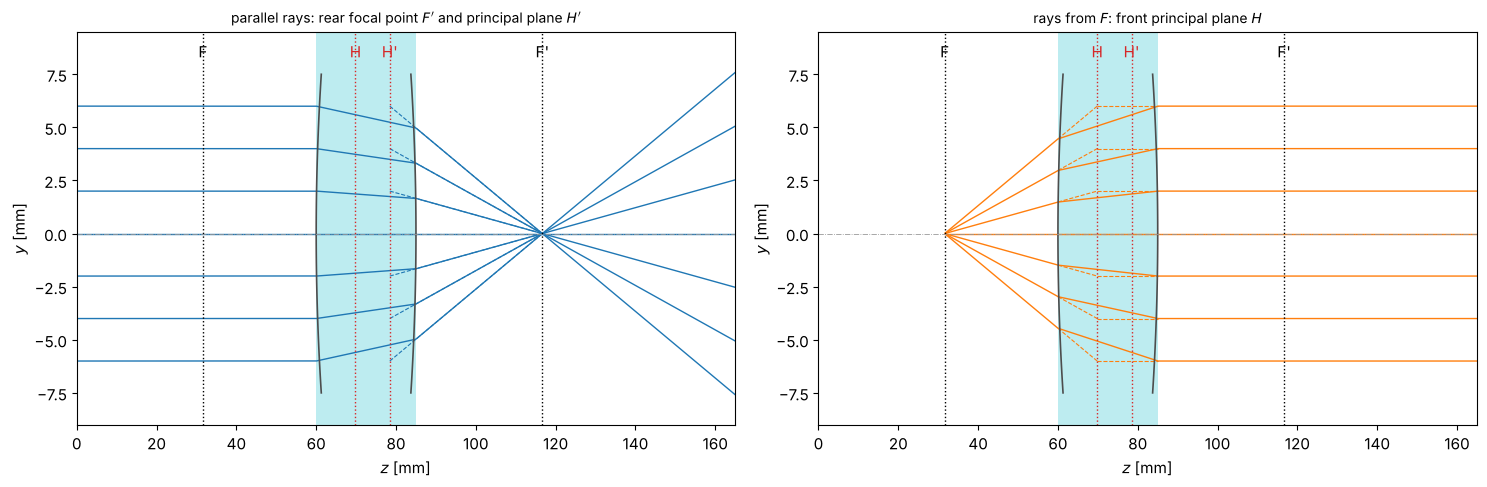

In [4]:
R1, R2, d, n_glass = 60.0, -40.0, 25.0, 1.7
lens = OpticalSystem().thick_lens(R1, R2, d, n_glass)
cp = lens.cardinal_points()
print(f"EFL f' = {cp.f_prime:.2f} mm, BFL = {cp.bfl:.2f} mm, FFL = {cp.ffl:.2f} mm")
print(f"H = {cp.H:.2f} mm, H' = {cp.H_prime:.2f} mm (vertices at 0 and {d:.0f} mm)")
f_thin = 1/((n_glass - 1)*(1/R1 - 1/R2))
print(f"thin lens approximation: f = {f_thin:.2f} mm")

z_in, z_out = 60.0, 80.0
system = OpticalSystem().free_space(z_in).append(lens).free_space(z_out)
z = np.linspace(0, z_in + d + z_out, 800)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, from_front in zip(axes, (False, True)):
    heights = np.linspace(-6, 6, 7)
    if from_front:  # rays from the front focal point F
        z0 = z_in + cp.F
        sub = OpticalSystem().free_space(z_in - z0).append(lens).free_space(z_out)
        ang = heights/(cp.H - cp.F)  # rays that would reach the height h in H
        y, _ = sub.trace(np.vstack([np.zeros_like(ang), ang]), z - z0)
        mask = z >= z0
        ax.plot(z[mask], y[mask], "C1", lw=1)
        for h in heights:
            # extension of the incident ray to H and of the exit ray back to H:
            ax.plot([z_in, z_in + cp.H], [h*(z_in - z0)/(cp.H - cp.F), h], "C1--", lw=0.8)
            ax.plot([z_in + cp.H, z_in + d], [h, h], "C1--", lw=0.8)
    else:
        rays = np.vstack([heights, np.zeros_like(heights)])
        y, theta = system.trace(rays, z)
        for i in range(len(heights)):
            ax.plot(z, y[:, i], "C0", lw=1)
            # extension of the exit ray back to the incident height:
            zz = np.array([z_in + cp.H_prime, z_in + cp.F_prime])
            ax.plot(zz, [heights[i], 0], "C0--", lw=0.8)
    ax.axvspan(z_in, z_in + d, color="C9", alpha=0.15, lw=0)
    for name, zz, c in (("F", cp.F, "k"), ("H", cp.H, "C3"), ("H'", cp.H_prime, "C3"), ("F'", cp.F_prime, "k")):
        ax.axvline(z_in + zz, color=c, ls=":", lw=1)
        ax.text(z_in + zz, 8.3, name, ha="center", color=c)
    lens_draw = OpticalSystem().free_space(z_in).append(lens)
    lens_draw.draw(ax, height=7.5)
    ax.set_ylim(-9, 9.5); ax.set_xlim(z[0], z[-1])
    ax.set_xlabel("$z$ [mm]"); ax.set_ylabel("$y$ [mm]")
axes[0].set_title("parallel rays: rear focal point $F'$ and principal plane $H'$", fontsize=10)
axes[1].set_title("rays from $F$: front principal plane $H$", fontsize=10)
fig.tight_layout()

How do the principal planes move when the lens gets thicker? For a
biconvex lens they move inwards and cross; for a meniscus lens (both radii
of the same sign) they can even lie outside the glass. This is how telephoto
and retrofocus designs put the principal plane in front of or behind the
lens. Grey band: the glass.

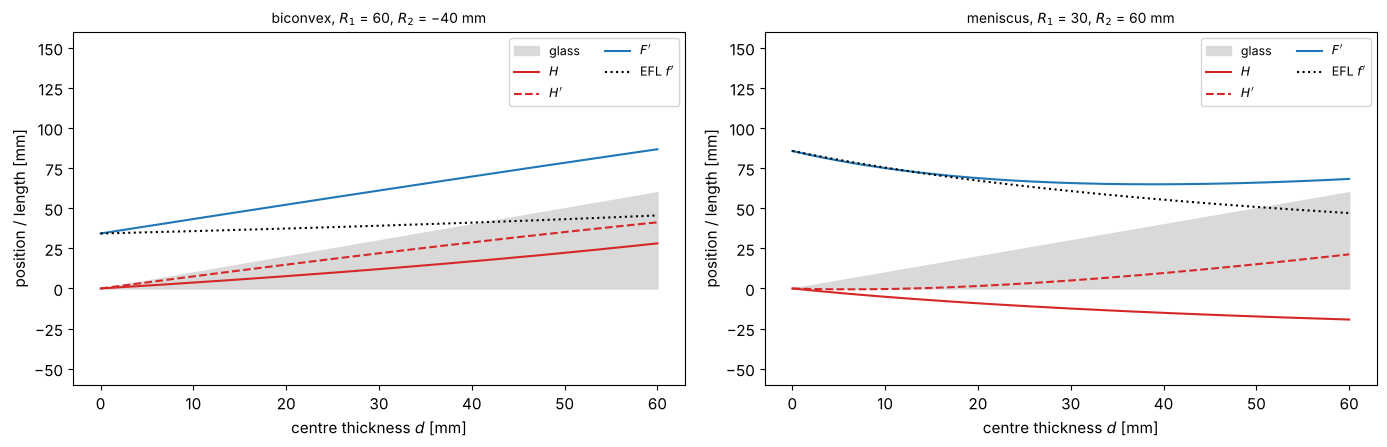

In [5]:
thicknesses = np.linspace(0.01, 60, 300)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, (r1, r2, title) in zip(axes, ((60.0, -40.0, "biconvex, $R_1$ = 60, $R_2$ = −40 mm"),
                                      (30.0, 60.0, "meniscus, $R_1$ = 30, $R_2$ = 60 mm"))):
    pts = [OpticalSystem().thick_lens(r1, r2, t, n_glass).cardinal_points() for t in thicknesses]
    ax.fill_between(thicknesses, 0, thicknesses, color="0.85", label="glass")
    ax.plot(thicknesses, [p.H for p in pts], "C3", label="$H$")
    ax.plot(thicknesses, [p.H_prime for p in pts], "C3--", label="$H'$")
    ax.plot(thicknesses, [p.F_prime for p in pts], "C0", label="$F'$")
    ax.plot(thicknesses, [p.f_prime for p in pts], "k:", label="EFL $f'$")
    ax.set_ylim(-60, 160); ax.set_xlabel("centre thickness $d$ [mm]"); ax.set_ylabel("position / length [mm]")
    ax.set_title(title, fontsize=10); ax.legend(fontsize=9, ncol=2)
fig.tight_layout()

## 3. Two lenses: effective focal length, telescope and lens waveguide

Two thin lenses at a distance $d$ have $1/f = 1/f_1 + 1/f_2 - d/(f_1 f_2)$. For
$d = f_1 + f_2$ the system is afocal ($C = 0$): a Kepler telescope that turns a
parallel bundle into a narrower parallel bundle with angular magnification
$-f_1/f_2$. The right panel shows the focal length and the back focal length
against $d$ for a positive/negative pair (a telephoto lens): the back focal
length can be much shorter than the focal length, and the whole lens
(length $d$ + BFL) shorter than a single lens of the same focal length.

Kepler telescope matrix (lens to lens):
[[ -0.4 140. ]
 [  0.   -2.5]]


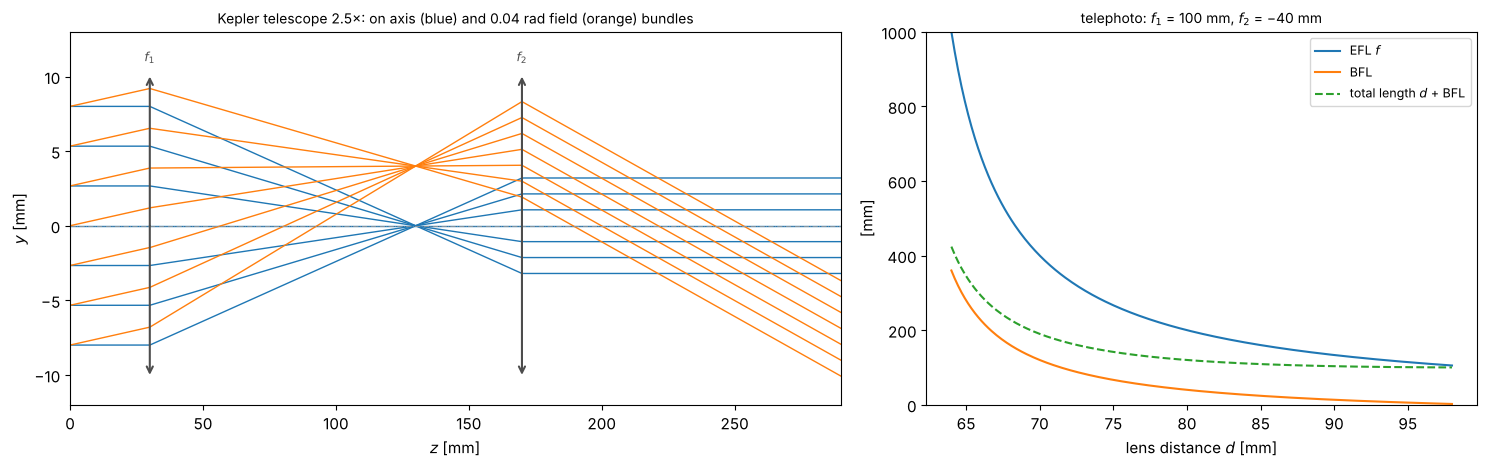

In [6]:
f1, f2 = 100.0, 40.0
kepler = OpticalSystem().free_space(30).thin_lens(f1, "$f_1$").free_space(f1 + f2).thin_lens(f2, "$f_2$").free_space(120)
print("Kepler telescope matrix (lens to lens):")
print(np.round(OpticalSystem().thin_lens(f1).free_space(f1 + f2).thin_lens(f2).matrix, 6) + 0.0)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
z = np.linspace(0, kepler.length, 600)
heights = np.linspace(-8, 8, 7)
plot_rays(axes[0], kepler, np.vstack([heights, np.zeros(7)]), z, colors=["C0"]*7, lw=1)
plot_rays(axes[0], kepler, np.vstack([heights, np.full(7, 0.04)]), z, colors=["C1"]*7, lw=1)
kepler.draw(axes[0], height=10)
axes[0].set_ylim(-12, 13); axes[0].set_xlim(0, kepler.length)
axes[0].set_xlabel("$z$ [mm]"); axes[0].set_ylabel("$y$ [mm]")
axes[0].set_title("Kepler telescope 2.5×: on axis (blue) and 0.04 rad field (orange) bundles", fontsize=10)

f1, f2 = 100.0, -40.0
d = np.linspace(64, 98, 300)  # f > 0 needs d > f1 + f2 = 60 mm
efl = 1/(1/f1 + 1/f2 - d/(f1*f2))
bfl = [OpticalSystem().thin_lens(f1).free_space(dd).thin_lens(f2).cardinal_points().bfl for dd in d]
axes[1].plot(d, efl, label="EFL $f$"); axes[1].plot(d, bfl, label="BFL")
axes[1].plot(d, d + np.array(bfl), "--", label="total length $d$ + BFL")
axes[1].set_ylim(0, 1000)
axes[1].set_xlabel("lens distance $d$ [mm]"); axes[1].set_ylabel("[mm]")
axes[1].set_title("telephoto: $f_1$ = 100 mm, $f_2$ = −40 mm", fontsize=10); axes[1].legend(fontsize=9)
fig.tight_layout()

A periodic sequence of identical lenses at distance $d$ guides rays only if
the matrix of one period satisfies $|(A + D)/2| = |1 - d/(2f)| < 1$, i.e.
$0 < d < 4f$: the same stability condition as for an optical resonator
(section 9). Inside the stable range, rays oscillate with the phase advance
$\arccos(1 - d/2f)$ per period; outside, they run away exponentially.

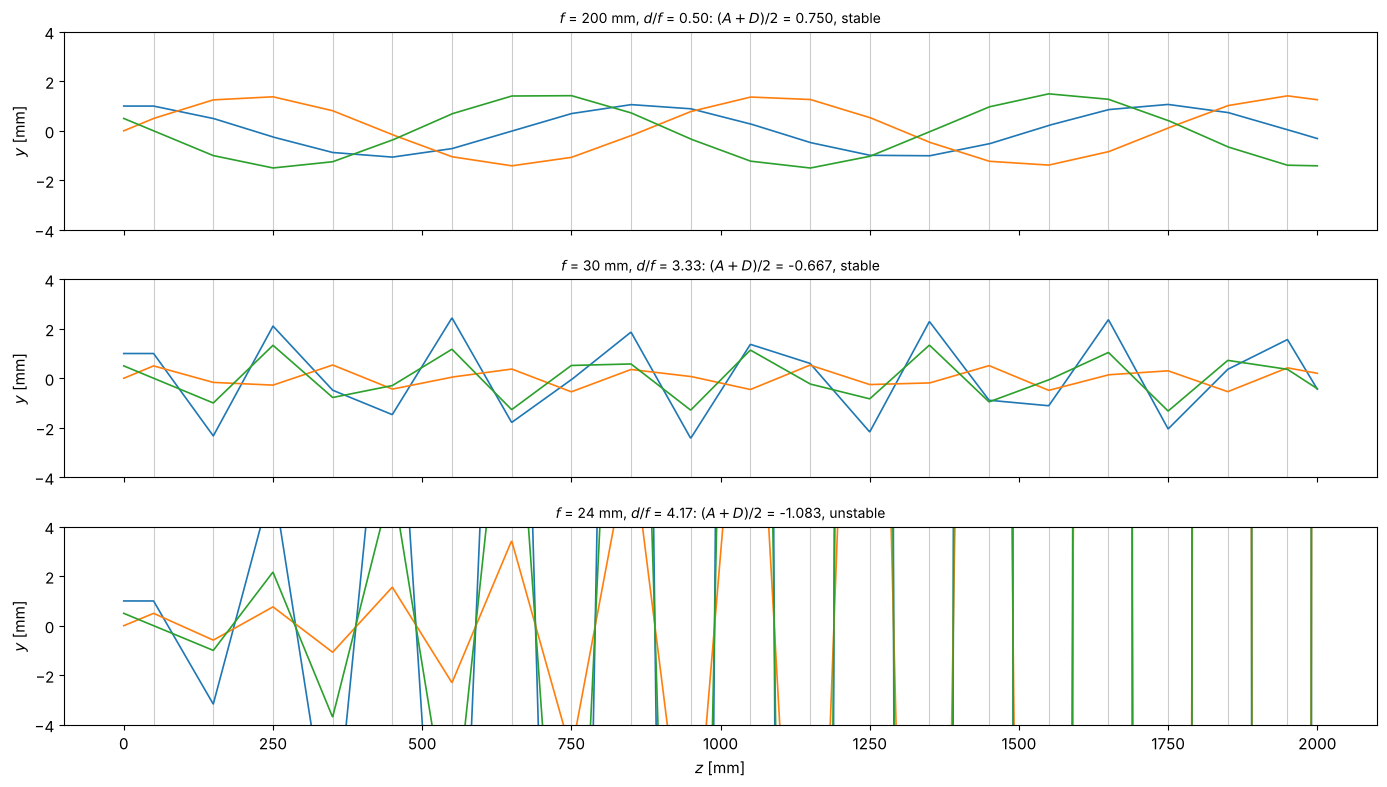

In [7]:
d = 100.0
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, f in zip(axes, (200.0, 30.0, 24.0)):
    guide = OpticalSystem()
    for i in range(20):
        guide.free_space(d/2).thin_lens(f).free_space(d/2)
    period = OpticalSystem().free_space(d/2).thin_lens(f).free_space(d/2).matrix
    mm = abcd.stability_parameter(period)
    z = np.linspace(0, guide.length, 2000)
    plot_rays(ax, guide, np.array([[1.0, 0.0, 0.5], [0.0, 0.01, -0.01]]), z, colors=["C0", "C1", "C2"], lw=1.2)
    for e in guide.elements:
        if e.kind == "lens":
            ax.axvline(e.z, color="0.8", lw=0.8, zorder=0)
    ax.set_ylim(-4, 4); ax.set_ylabel("$y$ [mm]")
    state = "stable" if abs(mm) < 1 else "unstable"
    ax.set_title(f"$f$ = {f:.0f} mm, $d/f$ = {d/f:.2f}: $(A + D)/2$ = {mm:.3f}, {state}", fontsize=10)
axes[-1].set_xlabel("$z$ [mm]")
fig.tight_layout()

## 4. GRIN lenses

In a graded index medium $n(r) = n_0(1 - g^2 r^2/2)$, rays follow sine curves
with the pitch $P = 2\pi/g$. A quarter pitch rod focuses a parallel bundle onto
its back surface and collimates a point source on its front surface; half a
pitch images with $m = -1$. `OpticalSystem.trace()` evaluates the rays inside
the rod.

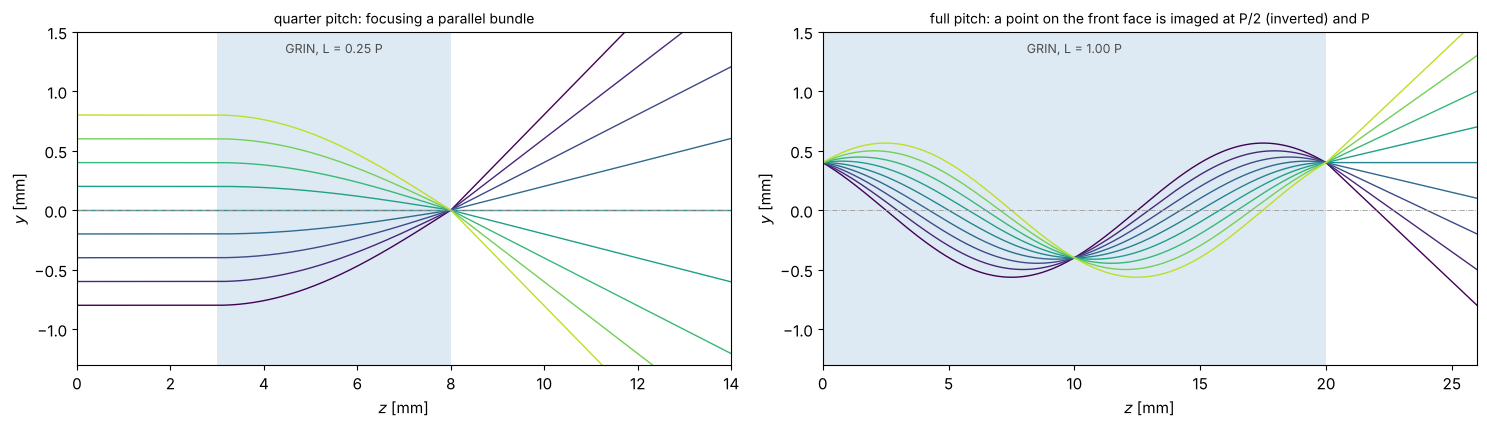

In [8]:
n0, g = 1.6, 2*np.pi/20.0  # pitch 20 mm
P = 2*np.pi/g
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for ax, (length, d_front, rays, title) in zip(axes, (
        (P/4, 3.0, np.vstack([np.linspace(-0.8, 0.8, 9), np.zeros(9)]), "quarter pitch: focusing a parallel bundle"),
        (P, 0.0, np.vstack([np.full(9, 0.4), np.linspace(-0.2, 0.2, 9)]),
         "full pitch: a point on the front face is imaged at P/2 (inverted) and P"))):
    system = OpticalSystem().free_space(d_front).grin(length, n0, g, label=f"GRIN, L = {length/P:.2f} P").free_space(6, n=1.0)
    z = np.linspace(0, system.length, 800)
    y = plot_rays(ax, system, rays, z, colors=plt.cm.viridis(np.linspace(0, 0.9, 9)), lw=1)
    system.draw(ax, height=1.2)
    ax.set_xlim(0, system.length); ax.set_ylim(-1.3, 1.5)
    ax.set_xlabel("$z$ [mm]"); ax.set_ylabel("$y$ [mm]"); ax.set_title(title, fontsize=10)
fig.tight_layout()

## 5. Gaussian beams in free space and in glass

From here on, lengths are in mm and the wavelength is that of a Nd:YAG laser,
λ = 1.064 µm. `trace_beam()` returns $q(z)$, the radius $w(z)$, the wavefront
radius $R(z)$ and the accumulated Gouy phase. Behind the waist they follow
$w = w_0\sqrt{1 + (z/z_R)^2}$, $R = z(1 + (z_R/z)^2)$ and $\psi = \arctan(z/z_R)$
(dashed). The beam enters a glass block ($n = 1.5$) at $z = 4$ mm: the Rayleigh
length grows to $n z_R$ and the beam diverges more slowly, while the Gouy
phase continues smoothly.

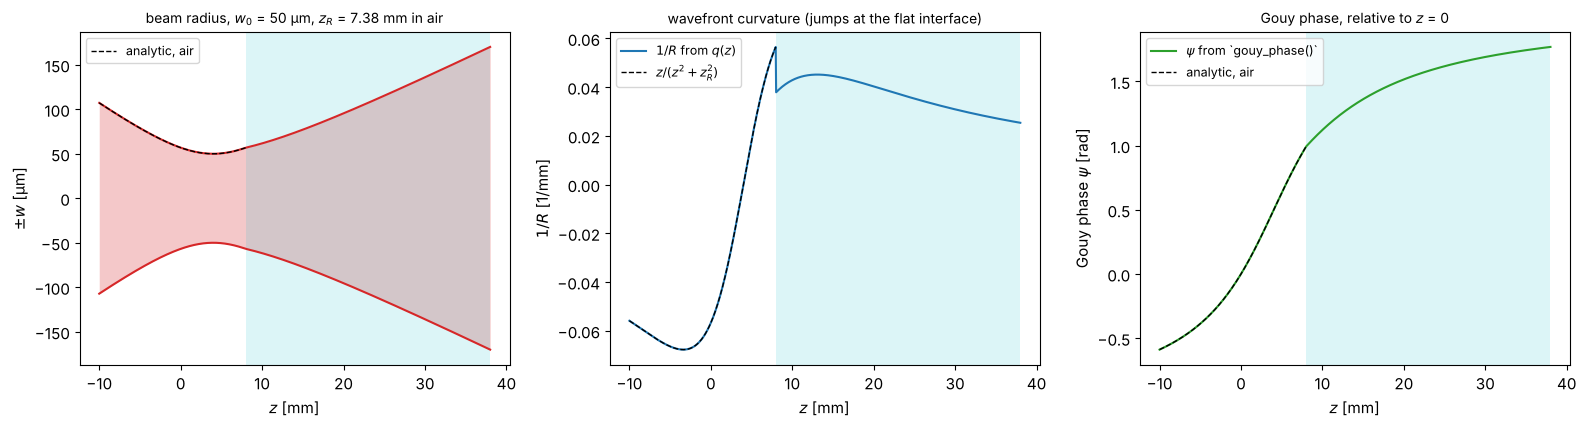

In [9]:
wl = 1.064e-3
w0 = 0.05
z_R = np.pi*w0**2/wl
q0 = abcd.q_from_waist(w0, -4.0, wl)  # waist 4 mm behind the input plane
system = OpticalSystem().free_space(8.0).free_space(30.0, n=1.5)
z = np.linspace(-10, 38, 1000)
beam = system.trace_beam(q0, wl, z)

zz = z - 4.0  # distance from the waist in air
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].fill_between(z, -beam.w*1e3, beam.w*1e3, color="C3", alpha=0.25, lw=0)
axes[0].plot(z, beam.w*1e3, "C3"); axes[0].plot(z, -beam.w*1e3, "C3")
air = z < 8
axes[0].plot(z[air], w0*np.sqrt(1 + (zz[air]/z_R)**2)*1e3, "k--", lw=1, label="analytic, air")
axes[0].axvspan(8, 38, color="C9", alpha=0.15, lw=0)
axes[0].set_ylabel("$\\pm w$ [µm]"); axes[0].legend(fontsize=9, loc="upper left")
axes[0].set_title(f"beam radius, $w_0$ = 50 µm, $z_R$ = {z_R:.2f} mm in air", fontsize=10)

axes[1].plot(z, 1/beam.R, "C0", label="$1/R$ from $q(z)$")
axes[1].plot(z[air], zz[air]/(zz[air]**2 + z_R**2), "k--", lw=1, label="$z/(z^2 + z_R^2)$")
axes[1].axvspan(8, 38, color="C9", alpha=0.15, lw=0)
axes[1].set_ylabel("$1/R$ [1/mm]"); axes[1].legend(fontsize=9)
axes[1].set_title("wavefront curvature (jumps at the flat interface)", fontsize=10)

axes[2].plot(z, beam.gouy, "C2", label="$\\psi$ from `gouy_phase()`")
axes[2].plot(z[air], np.arctan(zz[air]/z_R) - np.arctan(-4/z_R), "k--", lw=1, label="analytic, air")
axes[2].axvspan(8, 38, color="C9", alpha=0.15, lw=0)
axes[2].set_ylabel("Gouy phase $\\psi$ [rad]"); axes[2].legend(fontsize=9)
axes[2].set_title("Gouy phase, relative to $z$ = 0", fontsize=10)
for ax in axes:
    ax.set_xlabel("$z$ [mm]")
fig.tight_layout()

## 6. Focusing a Gaussian beam: where is the waist?

Geometrical optics puts the image of a waist at $1/s + 1/s' = 1/f$. Gaussian
beams obey Self's lens equation instead,
$1/(s + z_R^2/(s - f)) + 1/s' = 1/f$: the output waist position $s'$ (left)
never goes to infinity but has a maximum $f + f^2/(2 z_R)$ at $s = f + z_R$, and
for a waist *in* the front focal plane, the output waist lies in the rear
focal plane. The output waist radius (right) peaks at $s = f$ with
$w_0' = \lambda f/(\pi w_0)$. Both are computed here with `transform_q()` and
`waist()` only.

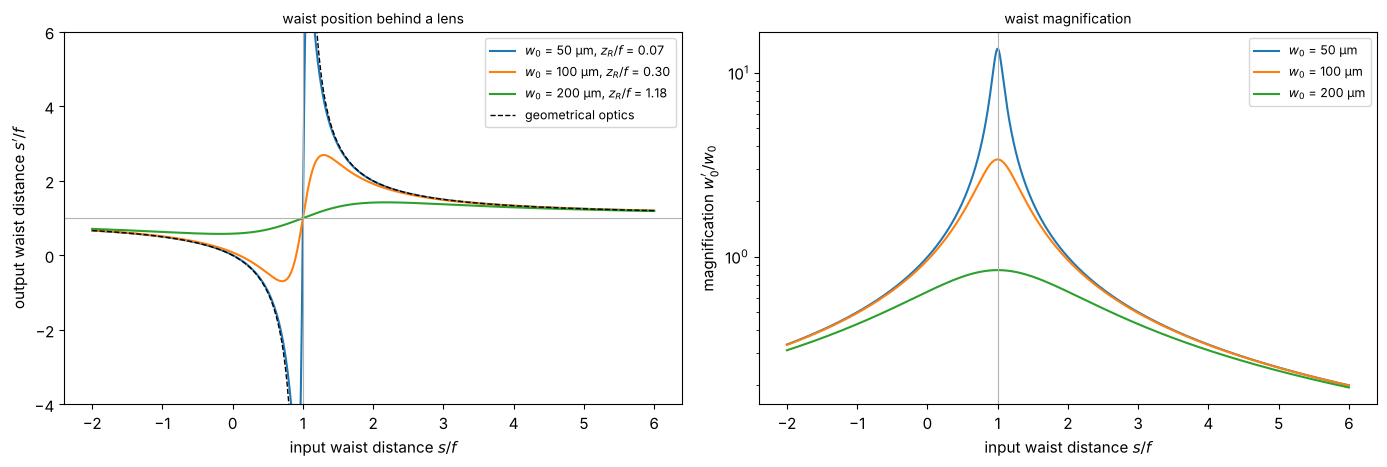

In [10]:
f = 100.0
s = np.linspace(-200, 600, 2001)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for w0, color in ((0.05, "C0"), (0.1, "C1"), (0.2, "C2")):
    zR = np.pi*w0**2/wl
    q_out = abcd.transform_q(abcd.thin_lens(f), abcd.q_from_waist(w0, s, wl))
    w0_out, s_out = abcd.waist(q_out, wl)
    axes[0].plot(s/f, s_out/f, color=color, label=f"$w_0$ = {w0*1e3:.0f} µm, $z_R/f$ = {zR/f:.2f}")
    axes[1].plot(s/f, w0_out/w0, color=color, label=f"$w_0$ = {w0*1e3:.0f} µm")
with np.errstate(divide="ignore"):
    s_geo = 1/(1/f - 1/s)
s_geo[np.abs(s - f) < 2] = np.nan
axes[0].plot(s/f, s_geo/f, "k--", lw=1, label="geometrical optics")
axes[0].set_ylim(-4, 6); axes[0].axhline(1, color="0.7", lw=0.8); axes[0].axvline(1, color="0.7", lw=0.8)
axes[0].set_xlabel("input waist distance $s/f$"); axes[0].set_ylabel("output waist distance $s'/f$")
axes[0].set_title("waist position behind a lens", fontsize=10); axes[0].legend(fontsize=9)
axes[1].set_yscale("log"); axes[1].axvline(1, color="0.7", lw=0.8)
axes[1].set_xlabel("input waist distance $s/f$"); axes[1].set_ylabel("magnification $w_0'/w_0$")
axes[1].set_title("waist magnification", fontsize=10); axes[1].legend(fontsize=9)
fig.tight_layout()

## 7. Collins integral: wave optics through an ABCD system

The Collins integral propagates any field through a paraxial system in one
step (`collins()`), here a Gaussian beam focused by a lens. Sweeping the
distance behind the lens gives the intensity $I(x, 0, z)$ through focus
(left; each $z$ shown on a common linear scale). The ABCD beam radius $\pm w(z)$
(dashed) lies on top of the wave optical $1/e^2$ contour. The right panel
compares the on-axis phase of the wave optical field with the Gouy phase
$-\psi(z)$ from `gouy_phase()`: they agree, including the jump of π through
the focus. The phase $kz$ along the axis is omitted by `collins()`.

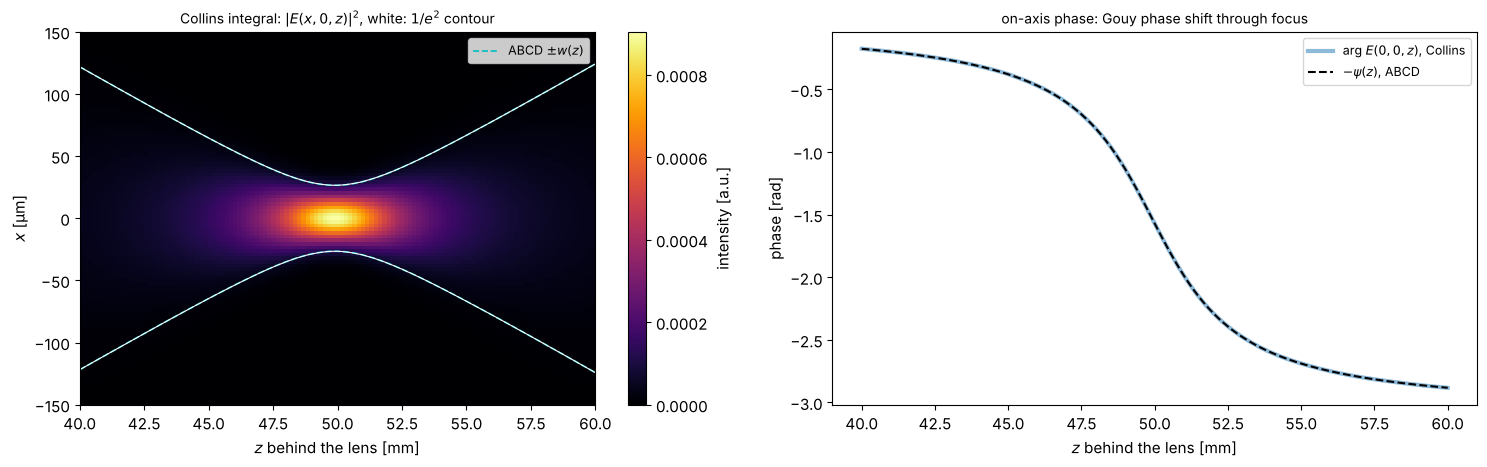

In [11]:
wl_um = 1.0  # µm for the wave optical grids
x, y, X, Y = grid2d(-1500, 1500, -1500, 1500, 1024)
w_in, f = 600.0, 50000.0
q_in = abcd.q_from_waist(w_in, 0.0, wl_um)
E_in = abcd.gaussian_field(x, y, q_in, wl_um)
z_values = np.linspace(40000, 60000, 121)
profiles, phase_axis, psi = [], [], []
for zz in z_values:
    M = OpticalSystem().thin_lens(f).free_space(zz).matrix
    E = abcd.collins(E_in, x, y, M, wl_um)
    profiles.append(np.abs(E[512])**2)
    phase_axis.append(np.angle(E[512, 512]))
    psi.append(abcd.gouy_phase(M, q_in))
profiles = np.array(profiles)
trace = OpticalSystem().thin_lens(f).free_space(70000).trace_beam(q_in, wl_um, z_values)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
im = axes[0].imshow(profiles.T, extent=(z_values[0]/1000, z_values[-1]/1000, x[0], x[-1]), aspect="auto", cmap="inferno")
axes[0].plot(z_values/1000, trace.w, "c--", lw=1.2, label="ABCD $\\pm w(z)$"); axes[0].plot(z_values/1000, -trace.w, "c--", lw=1.2)
axes[0].contour(z_values/1000, x, profiles.T/profiles.max(axis=1), levels=[np.exp(-2)], colors="w", linewidths=0.8)
axes[0].set_ylim(-150, 150); axes[0].set_xlabel("$z$ behind the lens [mm]"); axes[0].set_ylabel("$x$ [µm]")
axes[0].set_title("Collins integral: $|E(x, 0, z)|^2$, white: $1/e^2$ contour", fontsize=10); axes[0].legend(fontsize=9)
fig.colorbar(im, ax=axes[0], label="intensity [a.u.]")
axes[1].plot(z_values/1000, np.unwrap(phase_axis), "C0", lw=3, alpha=0.5, label="arg $E(0, 0, z)$, Collins")
axes[1].plot(z_values/1000, -np.unwrap(psi), "k--", label="$-\\psi(z)$, ABCD")
axes[1].set_xlabel("$z$ behind the lens [mm]"); axes[1].set_ylabel("phase [rad]")
axes[1].set_title("on-axis phase: Gouy phase shift through focus", fontsize=10); axes[1].legend(fontsize=9)
fig.tight_layout()

The Collins integral is not limited to Gaussian beams. A uniformly
illuminated circular aperture (radius 600 µm) in front of the same lens gives
the Airy pattern in the focal plane (left, right). Along the axis (centre,
logarithmic scale; the focus is much longer than wide) the intensity has
zeros where the aperture contains an integer number of Fresnel zone pairs as
seen from the axial point, $1/z = 1/f + 2m\lambda/a^2$. For a large Fresnel
number $N_F = a^2/(\lambda f)$ these are the familiar symmetric zeros at
$z - f \approx \mp 2m\lambda(f/a)^2$; here, $N_F = 7.2$ is small, and the focal
region is visibly asymmetric, with the intensity maximum shifted towards the
lens (focal shift). The focal plane $z = f$ is still an exact Fourier plane:
the system matrix from the aperture has $A = 0$.

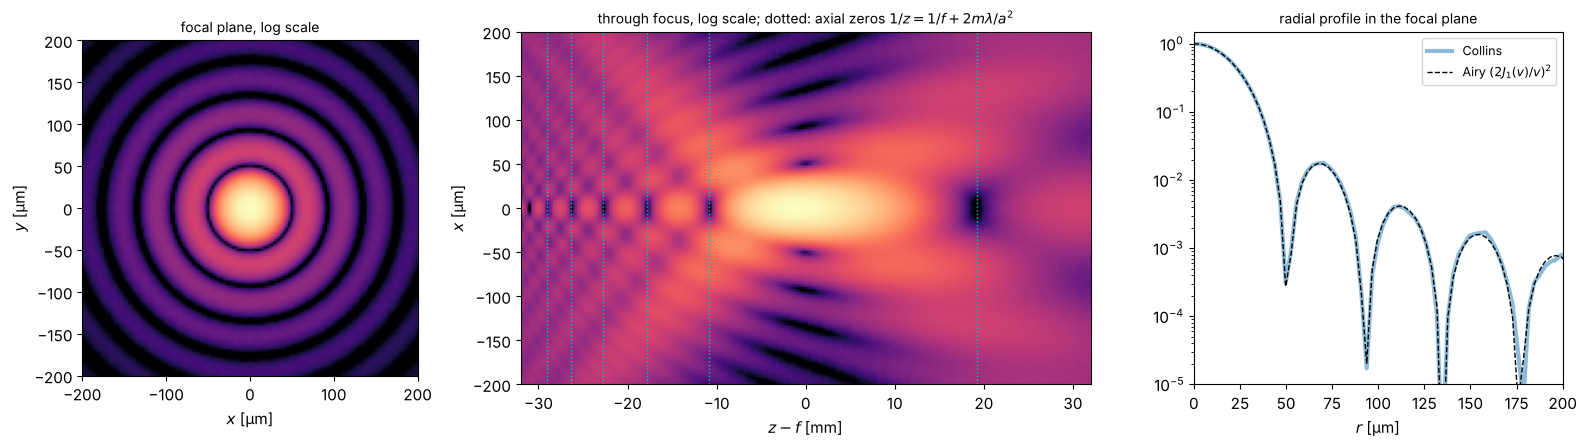

In [12]:
a = 600.0
E_ap = (np.hypot(X, Y) <= a).astype(complex)
dz = np.linspace(-32000, 32000, 161)
cuts = []
for zz in dz:
    E = abcd.collins(E_ap, x, y, OpticalSystem().thin_lens(f).free_space(f + zz).matrix, wl_um)
    cuts.append(np.abs(E[512])**2)
cuts = np.array(cuts)
E_focus = abcd.collins(E_ap, x, y, OpticalSystem().thin_lens(f).free_space(f).matrix, wl_um)
I_focus = np.abs(E_focus)**2

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1.7, 1.1]})
axes[0].imshow(I_focus/I_focus.max(), extent=(x[0], x[-1], y[0], y[-1]), cmap="magma", norm=LogNorm(1e-4, 1))
axes[0].set_xlim(-200, 200); axes[0].set_ylim(-200, 200)
axes[0].set_xlabel("$x$ [µm]"); axes[0].set_ylabel("$y$ [µm]"); axes[0].set_title("focal plane, log scale", fontsize=10)
axes[1].imshow(cuts.T/cuts.max(), extent=(dz[0]/1000, dz[-1]/1000, x[0], x[-1]), aspect="auto", cmap="magma", norm=LogNorm(1e-4, 1))
for m_zero in (-1, 1, 2, 3, 4, 5):
    axes[1].axvline((1/(1/f + 2*m_zero*wl_um/a**2) - f)/1000, color="c", ls=":", lw=1)
axes[1].set_xlim(dz[0]/1000, dz[-1]/1000); axes[1].set_ylim(-200, 200); axes[1].set_xlabel("$z - f$ [mm]"); axes[1].set_ylabel("$x$ [µm]")
axes[1].set_title("through focus, log scale; dotted: axial zeros $1/z = 1/f + 2m\\lambda/a^2$", fontsize=10)
from scipy.special import j1
r = x[512:]
v = 2*np.pi*a*r/(wl_um*f)
with np.errstate(invalid="ignore", divide="ignore"):
    airy = np.where(v > 0, (2*j1(v)/v)**2, 1.0)
axes[2].semilogy(r, I_focus[512, 512:]/I_focus.max(), "C0", lw=3, alpha=0.5, label="Collins")
axes[2].semilogy(r, airy, "k--", lw=1, label="Airy $(2J_1(v)/v)^2$")
axes[2].set_xlim(0, 200); axes[2].set_ylim(1e-5, 1.5)
axes[2].set_xlabel("$r$ [µm]"); axes[2].set_title("radial profile in the focal plane", fontsize=10); axes[2].legend(fontsize=9)
fig.tight_layout()

## 8. Mode matching into a single mode fibre

A collimated beam ($w = 1$ mm, λ = 1.064 µm) is to be coupled into a fibre with a
mode field radius of 3 µm, using a single lens of focal length $f$ at the
distance $d$ in front of the fibre facet. `coupling_efficiency()` gives the
overlap of the beam at the facet with the fibre mode (a waist on the facet).
The map shows that the best focal length is $f = \pi w w_\mathrm{fibre}/\lambda$,
and how sensitive the coupling is to the axial position of the lens. The
right panel shows cuts at three focal lengths.

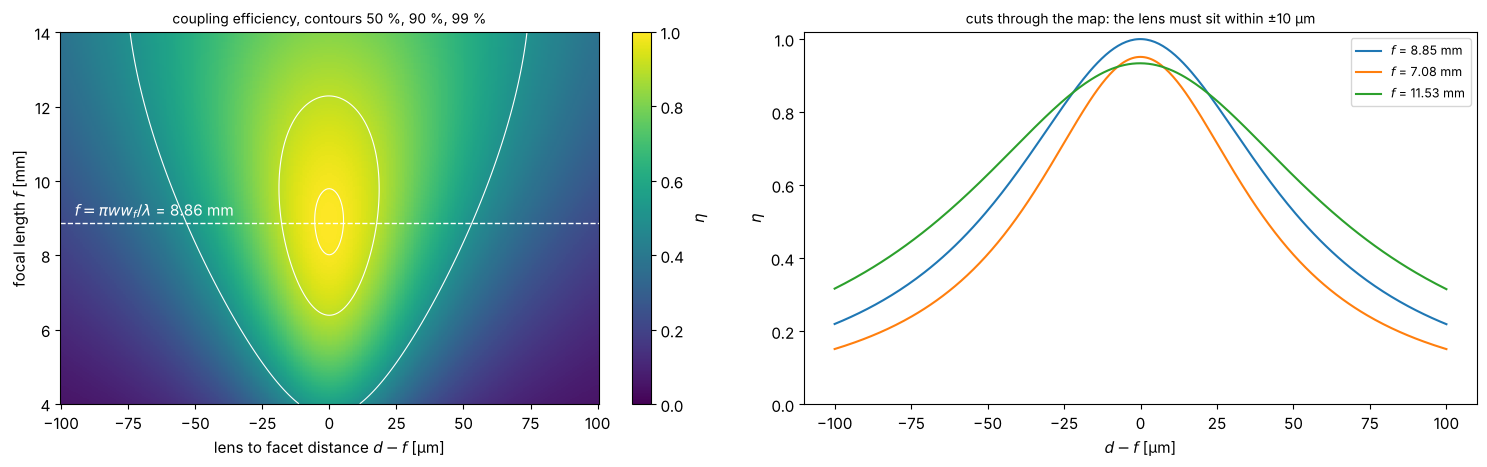

In [13]:
w_beam, w_fibre = 1.0, 3e-3
q_beam = abcd.q_from_waist(w_beam, 0.0, wl)
q_fibre = abcd.q_from_waist(w_fibre, 0.0, wl)
f_opt = np.pi*w_beam*w_fibre/wl
f_values = np.linspace(4, 14, 300)
dd = np.linspace(-0.1, 0.1, 301)  # distance relative to f
eta = np.empty((len(f_values), len(dd)))
for i, fv in enumerate(f_values):
    for j, ddj in enumerate(dd):
        M = abcd.compose(abcd.thin_lens(fv), abcd.free_space(fv + ddj))
        eta[i, j] = abcd.coupling_efficiency(abcd.transform_q(M, q_beam), q_fibre, wl)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
im = axes[0].pcolormesh(dd*1000, f_values, eta, cmap="viridis", vmin=0, vmax=1, shading="auto")
axes[0].contour(dd*1000, f_values, eta, levels=[0.5, 0.9, 0.99], colors="w", linewidths=0.8)
axes[0].axhline(f_opt, color="w", ls="--", lw=1)
axes[0].text(-95, f_opt + 0.2, f"$f = \\pi w w_f/\\lambda$ = {f_opt:.2f} mm", color="w")
axes[0].set_xlabel("lens to facet distance $d - f$ [µm]"); axes[0].set_ylabel("focal length $f$ [mm]")
axes[0].set_title("coupling efficiency, contours 50 %, 90 %, 99 %", fontsize=10)
fig.colorbar(im, ax=axes[0], label="$\\eta$")
for fv, color in ((f_opt, "C0"), (f_opt*0.8, "C1"), (f_opt*1.3, "C2")):
    i = np.argmin(np.abs(f_values - fv))
    axes[1].plot(dd*1000, eta[i], color=color, label=f"$f$ = {f_values[i]:.2f} mm")
axes[1].set_xlabel("$d - f$ [µm]"); axes[1].set_ylabel("$\\eta$"); axes[1].set_ylim(0, 1.02)
axes[1].set_title("cuts through the map: the lens must sit within ±10 µm", fontsize=10); axes[1].legend(fontsize=9)
fig.tight_layout()

## 9. Optical resonators

### Stability diagram

A two mirror resonator of length $L$ with radii $R_1, R_2$ is stable for
$0 < g_1 g_2 < 1$, $g_i = 1 - L/R_i$. The colour gives the radius of the
eigenmode on mirror 1, $w_1^2 = (\lambda L/\pi)\sqrt{g_2/(g_1(1 - g_1 g_2))}$,
computed with `eigenmode()` from the round trip matrix (mirror 1 → mirror 2 →
mirror 1, unfolded). The mode becomes large near the edges of the stable
region: plane-parallel (P), concentric (C) and the plane-concave limit. The
confocal resonator (K) at $g_1 = g_2 = 0$ has the smallest mode for its length.

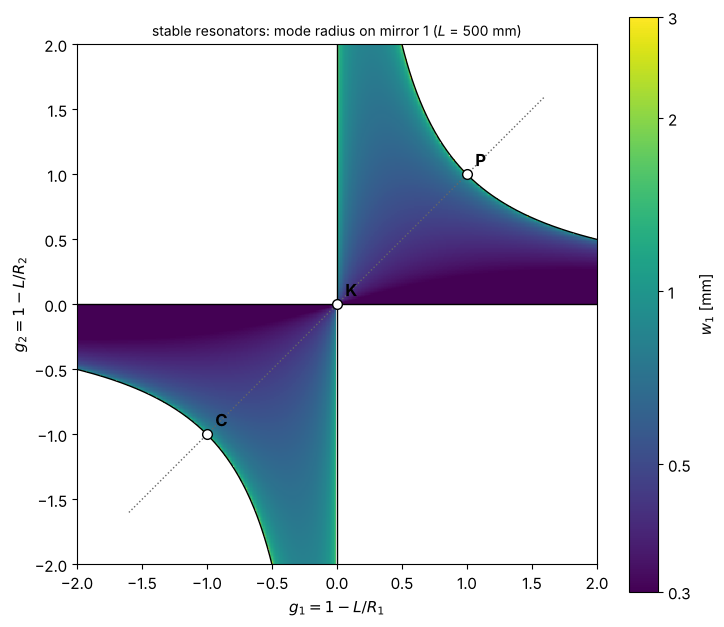

In [14]:
L = 500.0
g = np.linspace(-2, 2, 401)
G1, G2 = np.meshgrid(g, g)
w1 = np.full(G1.shape, np.nan)
np.seterr(divide="ignore")  # R = inf for g = 1
for i in range(len(g)):
    for j in range(len(g)):
        g1, g2 = G1[i, j], G2[i, j]
        if 0 < g1*g2 < 1:
            R1, R2 = L/(1 - g1), L/(1 - g2)
            M = OpticalSystem().free_space(L).mirror(R2).free_space(L).mirror(R1).matrix
            w1[i, j] = abcd.beam_radius(abcd.eigenmode(M), wl)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.pcolormesh(G1, G2, w1, cmap="viridis", norm=LogNorm(0.3, 3), shading="auto")
gg = np.linspace(0.02, 2, 200)
ax.plot(gg, 1/gg, "k", lw=1); ax.plot(-gg, -1/gg, "k", lw=1)
ax.axhline(0, color="k", lw=1); ax.axvline(0, color="k", lw=1)
ax.plot([-1.6, 1.6], [-1.6, 1.6], color="0.4", ls=":", lw=1)
for (g1, g2), name in (((1, 1), "P"), ((0, 0), "K"), ((-1, -1), "C")):
    ax.plot(g1, g2, "wo", mec="k", ms=7)
    ax.annotate(name, (g1, g2), xytext=(6, 6), textcoords="offset points", fontsize=12, weight="bold")
ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal")
ax.set_xlabel("$g_1 = 1 - L/R_1$"); ax.set_ylabel("$g_2 = 1 - L/R_2$")
ax.set_title(f"stable resonators: mode radius on mirror 1 ($L$ = {L:.0f} mm)", fontsize=10)
cb = fig.colorbar(im, ax=ax, label="$w_1$ [mm]", ticks=[0.3, 0.5, 1, 2, 3])
cb.ax.set_yticklabels(["0.3", "0.5", "1", "2", "3"]); cb.ax.minorticks_off()
fig.tight_layout()

### Eigenmodes inside resonators

Mode radius along the axis of four resonators of length 500 mm, from
`trace_beam()` over one round trip starting at mirror 1. The eigenmode
reproduces itself after the round trip, and its wavefronts match the mirror
radii (printed). The round trip Gouy phase $\Delta\psi = 2\arccos(\pm\sqrt{g_1 g_2})$
sets the frequency offset of the transverse modes $\mathrm{TEM}_{mn}$ from the
fundamental mode, $\Delta\nu = (m + n)\,\Delta\psi/(2\pi)\cdot\mathrm{FSR}$.

near plane-parallel, $R$ = 10 m : w1 =  736.4 µm, w2 =  736.4 µm, R(q) at mirror 2 =   10.000 m, round trip Gouy phase =   36.4°
plane-concave, $R_2$ = 1 m      : w1 =  411.5 µm, w2 =  582.0 µm, R(q) at mirror 2 =    1.000 m, round trip Gouy phase =   90.0°
near confocal, $R$ = 0.51 m     : w1 =  411.6 µm, w2 =  411.6 µm, R(q) at mirror 2 =    0.510 m, round trip Gouy phase =  177.8°
near concentric, $R$ = 0.26 m   : w1 =  663.5 µm, w2 =  663.5 µm, R(q) at mirror 2 =    0.260 m, round trip Gouy phase =  314.8°


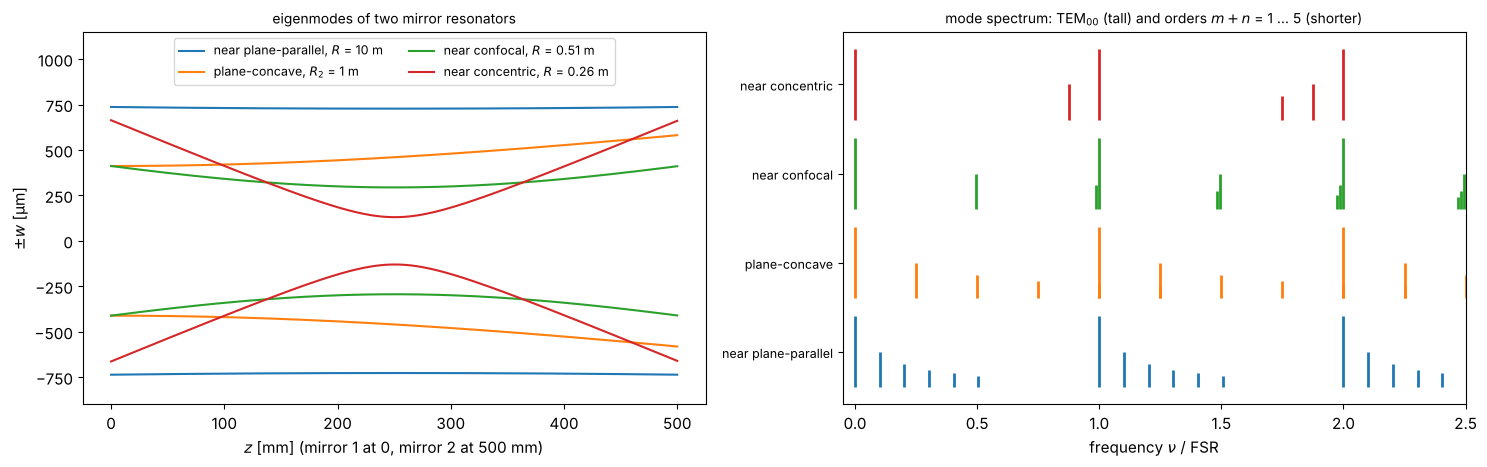

In [15]:
configs = {"near plane-parallel, $R$ = 10 m": (10000.0, 10000.0),
           "plane-concave, $R_2$ = 1 m": (np.inf, 1000.0),
           "near confocal, $R$ = 0.51 m": (510.0, 510.0),
           "near concentric, $R$ = 0.26 m": (260.0, 260.0)}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
z = np.linspace(0, L, 400)
spectra = {}
for (name, (R1, R2)), color in zip(configs.items(), ("C0", "C1", "C2", "C3")):
    round_trip = OpticalSystem().free_space(L).mirror(R2).free_space(L).mirror(R1)
    M = round_trip.matrix
    q = abcd.eigenmode(M)
    beam = round_trip.trace_beam(q, wl, np.linspace(0, 2*L, 801))
    axes[0].plot(z, beam.w[:400]*1e3, color=color, label=name)
    axes[0].plot(z, -beam.w[:400]*1e3, color=color)
    dpsi = abcd.round_trip_gouy_phase(M)
    spectra[name] = (dpsi, color)
    q2 = abcd.transform_q(abcd.free_space(L), q)  # arriving at mirror 2
    R_at_2 = abcd.curvature_radius(q2)
    print(f"{name:32s}: w1 = {beam.w[0]*1e3:6.1f} µm, w2 = {abcd.beam_radius(q2, wl)*1e3:6.1f} µm, "
          f"R(q) at mirror 2 = {R_at_2/1000:8.3f} m, round trip Gouy phase = {np.rad2deg(dpsi):6.1f}°")
axes[0].set_xlabel("$z$ [mm] (mirror 1 at 0, mirror 2 at 500 mm)"); axes[0].set_ylabel("$\\pm w$ [µm]")
axes[0].set_title("eigenmodes of two mirror resonators", fontsize=10); axes[0].legend(fontsize=9, loc="upper center", ncol=2)
axes[0].set_ylim(-900, 1150)

for k, (name, (dpsi, color)) in enumerate(spectra.items()):
    for q_long in range(3):
        for order in range(6):
            nu = q_long + order*dpsi/(2*np.pi)
            if nu <= 2.5:
                axes[1].vlines(nu, k, k + 0.8/(1 + order), color=color, lw=2)
axes[1].set_yticks(np.arange(4) + 0.4); axes[1].set_yticklabels([n.split(",")[0] for n in spectra], fontsize=9)
axes[1].set_xlabel("frequency $\\nu$ / FSR"); axes[1].set_xlim(-0.05, 2.5)
axes[1].set_title("mode spectrum: TEM$_{00}$ (tall) and orders $m + n$ = 1 … 5 (shorter)", fontsize=10)
fig.tight_layout()

The near plane-parallel and near concentric resonators have nearly degenerate
transverse modes (Gouy phase near 0 or 360°); the confocal resonator is
degenerate: the exactly confocal resonator ($g_1 = g_2 = 0$, Gouy
phase 180°) sits on the border of the stability diagram, and the odd orders
of the near confocal one fall almost halfway between the longitudinal modes.

### A folded resonator with astigmatism

A concave mirror used at an angle $\theta$ focuses with $R\cos\theta/2$ in the
plane of incidence (tangential) and with $R/(2\cos\theta)$ perpendicular to it
(sagittal). Consider a folded three mirror resonator: plane end mirror, 52 mm
to a folding mirror with $R = 100$ mm, arm length $d$ to a second plane end
mirror. Without folding it is stable for $f < d < f + f^2/(52\,\mathrm{mm} - f)$,
$f = 50$ mm. Folding by 20° moves the tangential focal length below and the
sagittal one above 52 mm: the two stability ranges then overlap only between
$d = 47$ and 53 mm. The fold angle is a design knob that has to be included
in the design of any folded laser cavity. Bottom: tangential and sagittal
mode radii on the first end mirror.

θ =  0°: f_t = 50.0 mm, f_s = 50.0 mm, stable in both planes for 50.0 < d < 120.0 mm (plotted range)
θ = 10°: f_t = 49.2 mm, f_s = 50.8 mm, stable in both planes for 50.8 < d < 120.0 mm (plotted range)


θ = 20°: f_t = 47.0 mm, f_s = 53.2 mm, stable in both planes for 47.0 < d < 53.2 mm (plotted range)
θ = 30°: f_t = 43.3 mm, f_s = 57.7 mm, stable in both planes for 43.4 < d < 57.7 mm (plotted range)


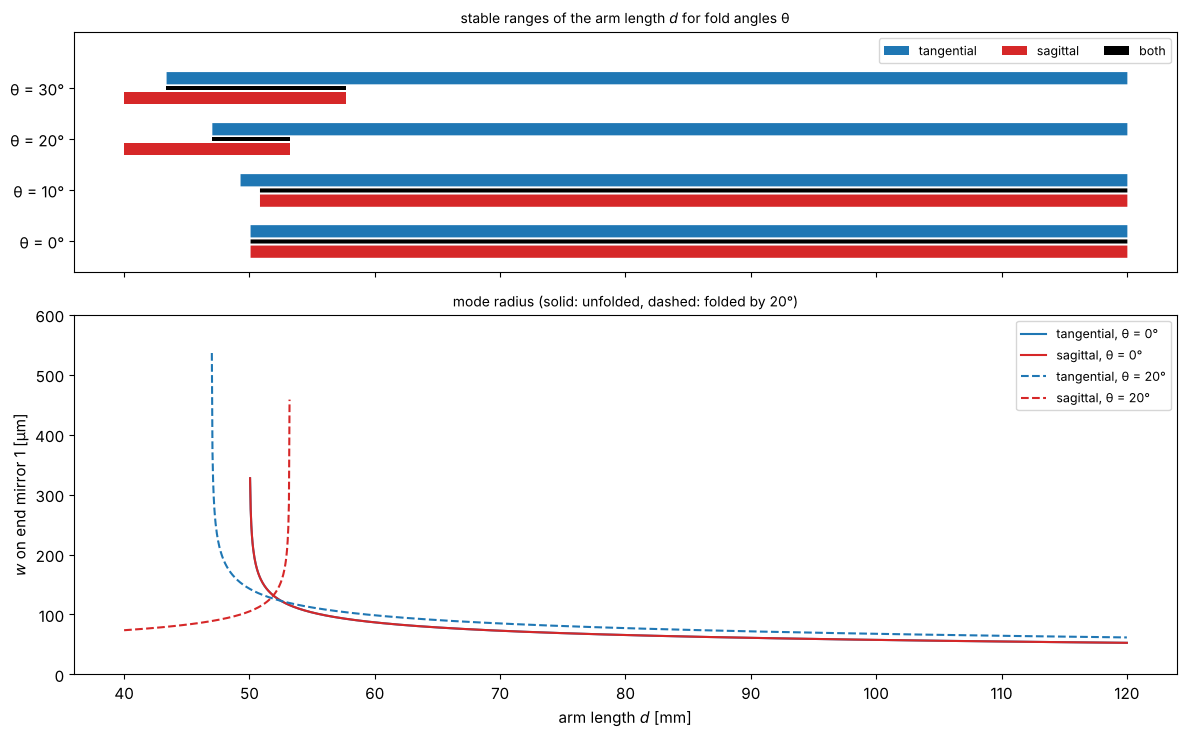

In [16]:
R_fold, d1 = 100.0, 52.0

def round_trip(d, theta, plane):
    half = OpticalSystem().free_space(d1).mirror(R_fold, theta, plane).free_space(d)
    # plane end mirror, back through the fold, plane end mirror:
    return half.append(OpticalSystem().free_space(d).mirror(R_fold, theta, plane).free_space(d1)).matrix

d_values = np.linspace(40, 120, 1601)
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.5]})
angles = (0, 10, 20, 30)
for k, theta_deg in enumerate(angles):
    th = np.deg2rad(theta_deg)
    stable = {}
    for plane, color, offset in (("tangential", "C0", 0.2), ("sagittal", "C3", -0.2)):
        m_values = np.array([abcd.stability_parameter(round_trip(dv, th, plane)) for dv in d_values])
        stable[plane] = np.abs(m_values) < 1
        axes[0].fill_between(d_values, k + offset - 0.12, k + offset + 0.12, where=stable[plane], color=color, lw=0,
                             label=plane if k == 0 else None)
        if theta_deg in (0, 20):
            w = np.full_like(d_values, np.nan)
            for i, dv in enumerate(d_values):
                M = round_trip(dv, th, plane)
                if abcd.is_stable(M):
                    w[i] = abcd.beam_radius(abcd.eigenmode(M), wl)
            axes[1].plot(d_values, w*1e3, color=color, ls="-" if theta_deg == 0 else "--", label=f"{plane}, θ = {theta_deg}°")
    both = stable["tangential"] & stable["sagittal"]
    axes[0].fill_between(d_values, k - 0.04, k + 0.04, where=both, color="k", lw=0, label="both" if k == 0 else None)
    print(f"θ = {theta_deg:2d}°: f_t = {R_fold*np.cos(th)/2:.1f} mm, f_s = {R_fold/np.cos(th)/2:.1f} mm, "
          f"stable in both planes for {d_values[both].min():.1f} < d < {d_values[both].max():.1f} mm (plotted range)")
axes[0].set_yticks(range(len(angles))); axes[0].set_yticklabels([f"θ = {a}°" for a in angles])
axes[0].set_ylim(-0.6, len(angles) + 0.1)
axes[0].set_title("stable ranges of the arm length $d$ for fold angles θ", fontsize=10)
axes[0].legend(fontsize=9, ncol=3, loc="upper right")
axes[1].set_ylim(0, 600); axes[1].set_ylabel("$w$ on end mirror 1 [µm]"); axes[1].set_xlabel("arm length $d$ [mm]")
axes[1].set_title("mode radius (solid: unfolded, dashed: folded by 20°)", fontsize=10); axes[1].legend(fontsize=9)
fig.tight_layout()

## 10. Astigmatic focusing with the Collins integral

The same astigmatism shows up in wave optics. A round Gaussian beam
($w = 1$ mm) hits a concave mirror ($R = 1$ m) at 20°. `collins()` takes separate
matrices for $x$ (tangential) and $y$ (sagittal); the tangential focus lies
in front of the sagittal one, with a round spot (the "circle of least
confusion") between them. The waists lie a little closer to the mirror than
$f_t$ and $f_s$, by the Gaussian focal shift of section 6. The ABCD radii $w_x, w_y$ (lines) match the second
moment radii of the wave optical intensities (dots).

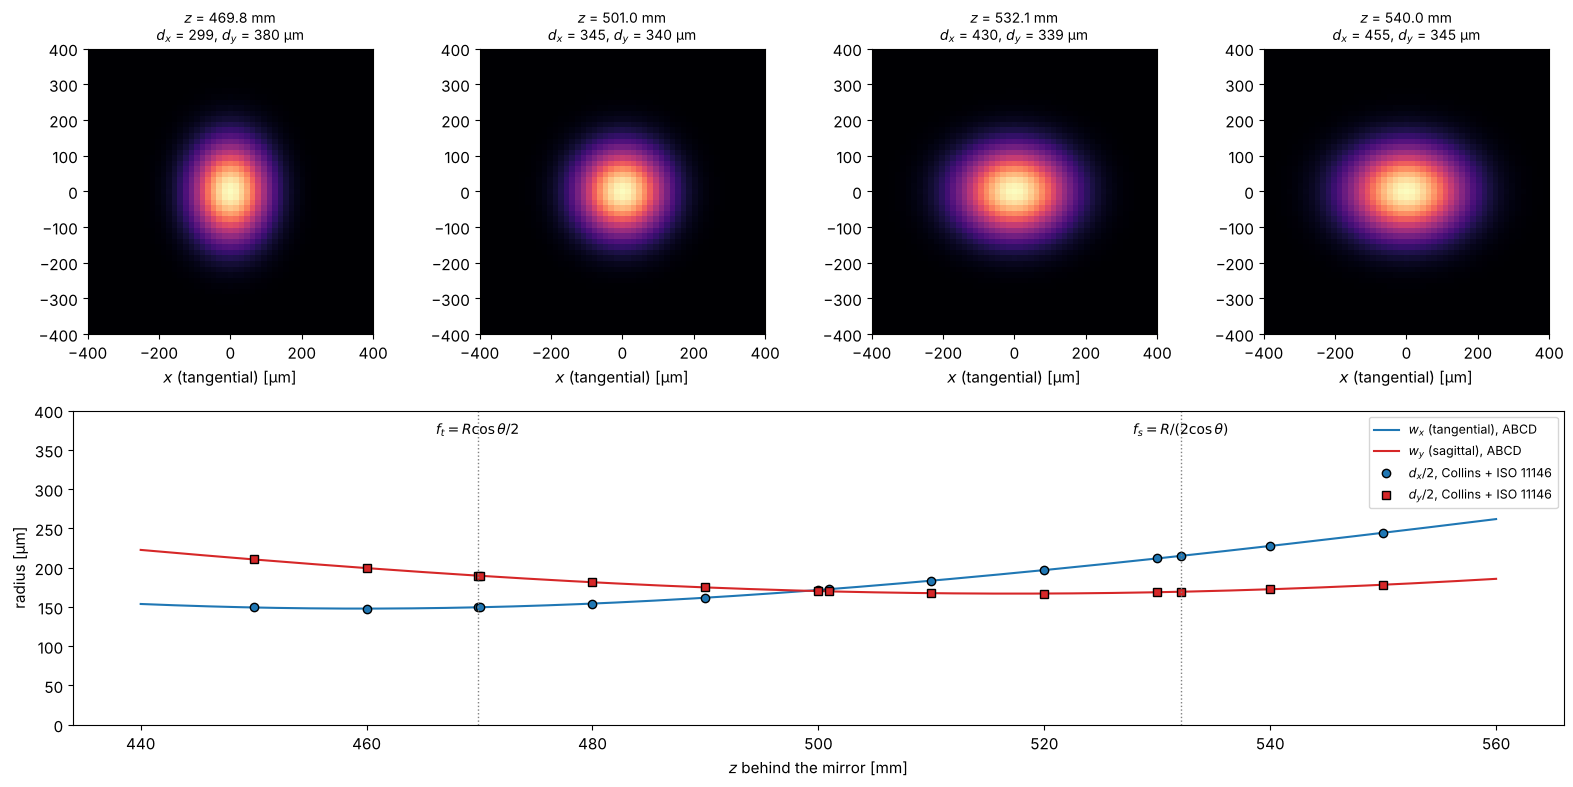

In [17]:
from pyoptics.beam_quality import beam_widths

x, y, X, Y = grid2d(-4000, 4000, -4000, 4000, 512)
q_in = abcd.q_from_waist(1000.0, 0.0, wl_um)
E_in = abcd.gaussian_field(x, y, q_in, wl_um)
R_m, theta = 1.0e6, np.deg2rad(20)
mirror_t = abcd.mirror(R_m, theta, "tangential")
mirror_s = abcd.mirror(R_m, theta, "sagittal")
f_t, f_s = R_m*np.cos(theta)/2, R_m/np.cos(theta)/2
z_values = np.linspace(440e3, 560e3, 241)
q_x = [abcd.transform_q(abcd.compose(mirror_t, abcd.free_space(zz)), q_in) for zz in z_values]
q_y = [abcd.transform_q(abcd.compose(mirror_s, abcd.free_space(zz)), q_in) for zz in z_values]
w_x, w_y = abcd.beam_radius(np.array(q_x), wl_um), abcd.beam_radius(np.array(q_y), wl_um)

z_show = [f_t, 0.5*(f_t + f_s), f_s, 540e3]
z_dots = np.linspace(450e3, 550e3, 11)
fig = plt.figure(figsize=(16, 8))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.1])
measured = []
for zz in sorted(set(np.concatenate([z_show, z_dots]))):
    E = abcd.collins(E_in, x, y, abcd.compose(mirror_t, abcd.free_space(zz)), wl_um,
                     M_y=abcd.compose(mirror_s, abcd.free_space(zz)))
    I = np.abs(E)**2
    b = beam_widths(I, x, y, iterate=False)
    measured.append((zz, b))
    if zz in z_show:
        ax = fig.add_subplot(gs[0, z_show.index(zz)])
        ax.imshow(I, extent=(x[0], x[-1], y[0], y[-1]), cmap="magma")
        ax.set_xlim(-400, 400); ax.set_ylim(-400, 400)
        ax.set_title(f"$z$ = {zz/1000:.1f} mm\n$d_x$ = {b.d_x:.0f}, $d_y$ = {b.d_y:.0f} µm", fontsize=10)
        ax.set_xlabel("$x$ (tangential) [µm]")
ax = fig.add_subplot(gs[1, :])
ax.plot(z_values/1000, w_x, "C0", label="$w_x$ (tangential), ABCD")
ax.plot(z_values/1000, w_y, "C3", label="$w_y$ (sagittal), ABCD")
zz_m = np.array([m_[0] for m_ in measured])
dx_m = []
for zz, b in measured:
    dx_m.append((b.d_x/2, b.d_y/2) if abs(b.phi) < np.pi/4 else (b.d_y/2, b.d_x/2))
dx_m = np.array(dx_m)
ax.plot(zz_m/1000, dx_m[:, 0], "o", color="C0", mec="k", label="$d_x/2$, Collins + ISO 11146")
ax.plot(zz_m/1000, dx_m[:, 1], "s", color="C3", mec="k", label="$d_y/2$, Collins + ISO 11146")
for zz, name in ((f_t, "$f_t = R\\cos\\theta/2$"), (f_s, "$f_s = R/(2\\cos\\theta)$")):
    ax.axvline(zz/1000, color="0.5", ls=":", lw=1); ax.text(zz/1000, 370, name, ha="center", fontsize=10)
ax.set_ylim(0, 400); ax.set_xlabel("$z$ behind the mirror [mm]"); ax.set_ylabel("radius [µm]")
ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()

## Summary

| Task | Tools |
|---|---|
| ray tracing, also inside GRIN and thick elements | `OpticalSystem` builders, `trace()`, `draw()` |
| focal lengths, principal and nodal points, images | `cardinal_points()`, `image()` |
| Gaussian beam radius, curvature and Gouy phase | `q_from_waist()`, `transform_q()`, `trace_beam()`, `gouy_phase()` |
| mode matching | `coupling_efficiency()` |
| resonators | `stability_parameter()`, `eigenmode()`, `round_trip_gouy_phase()`, `g_parameters()` |
| wave optics through any paraxial system | `collins()` (separate $x$ and $y$ matrices for astigmatic systems) |